# 06 · Ensembles

Averaging models with different inductive biases often helps a little. Here we average the saved
out-of-fold predictions of the best model from each family (same folds everywhere, so this is exactly
what an ensemble trained in each fold would predict). Averages are **geometric means** (mean in log space),
consistent with the log target.

- **Pre-chosen ensemble:** random forest + CatBoost + Tanimoto GP, one per family, picked before
  looking at ensemble scores. This is the honest estimate.
- **All 2- and 3-model combinations** of the candidate pool: exploratory only. Picking the best
  combination on the same folds overstates its score.

In [1]:
import itertools
import os
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cofreg import plots
from cofreg.cv import load_oof, pooled_scores, summarize
from cofreg.data import RESULTS_DIR, load_data

plots.style()
EXPERIMENT = "06_ensemble"
os.makedirs(os.path.join(RESULTS_DIR, EXPERIMENT), exist_ok=True)
y = load_data().capacity_max.to_numpy()

CANDIDATES = {
    "RF (estate+fg)": ("04_tree_models", "rf | estate+fg"),
    "RF (desc+ecfp+estate+fg)": ("04_tree_models", "rf | desc+ecfp+estate+fg"),
    "CatBoost (desc+ecfp+estate+fg)": ("04_tree_models", "catboost | desc+ecfp+estate+fg"),
    "GP Tanimoto+RBF": ("03_bayesian_models", "gp_tanimoto+rbf | ecfp+descriptor"),
    "TabPFN (rdkit+redox)": ("05_pretrained", "tabpfn | rdkit+redox"),
    "CheMeleon fine-tuned": ("05_pretrained", "chemeleon_finetune"),
}
PRECHOSEN = ("RF (estate+fg)", "CatBoost (desc+ecfp+estate+fg)", "GP Tanimoto+RBF")
oofs = {k: load_oof(*v)[1] for k, v in CANDIDATES.items()}


def geo_mean(names):
    return np.exp(np.mean([np.log(np.maximum(oofs[n], 1e-3)) for n in names], axis=0))

In [2]:
rows = []
for k in (1, 2, 3):
    for combo in itertools.combinations(CANDIDATES, k):
        rows.append({"model": " + ".join(combo), "size": k, "prechosen": combo == PRECHOSEN} | summarize(pooled_scores(y, geo_mean(combo))))
ens = pd.DataFrame(rows)
ens.to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary_all_combinations.csv"), index=False)

pre = ens[ens.prechosen | (ens["size"] == 1)].copy()
pre["experiment"], pre["features"] = EXPERIMENT, "-"
pre.loc[pre.prechosen, "model"] = "ensemble: " + pre.loc[pre.prechosen, "model"]
oof_pre = geo_mean(PRECHOSEN)
pd.DataFrame(oof_pre.T, columns=[f"repeat_{r}" for r in range(len(oof_pre))]).assign(y_true=y).to_csv(
    os.path.join(RESULTS_DIR, EXPERIMENT, "ensemble_rf_catboost_gp.csv"), index=False
)
pre[pre.prechosen].assign(model="ensemble_rf_catboost_gp").to_csv(os.path.join(RESULTS_DIR, EXPERIMENT, "summary.csv"), index=False)
pre[["model", "mape_mean", "pa_mean", "pa_std", "rmse_mean", "male_mean", "mape_ge20_mean", "r2_mean"]].round(3)

,model,mape_mean,pa_mean,pa_std,rmse_mean,male_mean,mape_ge20_mean,r2_mean
0,RF (estate+fg),1.397,0.677,0.008,187.035,0.688,0.606,0.086
1,RF (desc+ecfp+estate+fg),1.580,0.685,0.008,187.248,0.692,0.606,0.084
2,CatBoost (desc+ecfp+estate+fg),1.497,0.677,0.012,191.340,0.689,0.634,0.044
3,GP Tanimoto+RBF,1.577,0.663,0.007,194.219,0.704,0.667,0.015
4,TabPFN (rdkit+redox),1.652,0.677,0.007,183.113,0.678,0.670,0.124
5,CheMeleon fine-tuned,3.631,0.614,0.010,225.818,0.937,0.904,-0.333
25,ensemble: RF (estate+fg) + CatBoost (desc+ecfp...,1.437,0.681,0.008,188.665,0.673,0.610,0.070


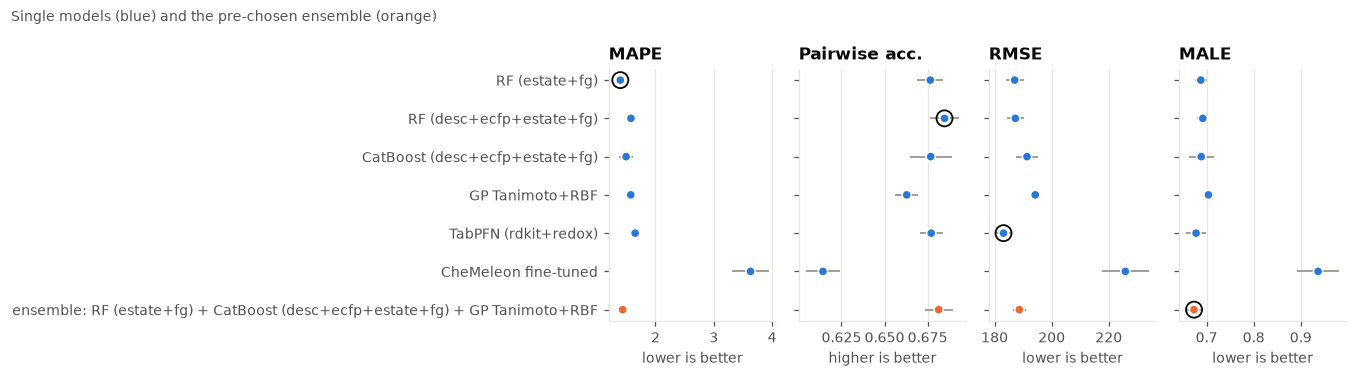

In [3]:
fig = plots.metric_dots(pre.reset_index(drop=True), highlight={m: plots.ORANGE for m in pre.loc[pre.prechosen, "model"]})
fig.suptitle("Single models (blue) and the pre-chosen ensemble (orange)", x=0.01, ha="left", fontsize=9, color=plots.INK_2)
fig.tight_layout()

## All combinations (exploratory)

Each dot is one ensemble. Pairwise accuracy against MALE: up and left is better.

,model,mape_mean,pa_mean,rmse_mean,male_mean
32,RF (desc+ecfp+estate+fg) + CatBoost (desc+ecfp...,1.527,0.685,185.559,0.667
1,RF (desc+ecfp+estate+fg),1.580,0.685,187.248,0.692
16,CatBoost (desc+ecfp+estate+fg) + TabPFN (rdkit...,1.523,0.685,185.171,0.662
22,RF (estate+fg) + RF (desc+ecfp+estate+fg) + GP...,1.469,0.684,187.715,0.681
21,RF (estate+fg) + RF (desc+ecfp+estate+fg) + Ca...,1.468,0.684,187.481,0.678
13,RF (desc+ecfp+estate+fg) + TabPFN (rdkit+redox),1.570,0.684,184.035,0.671
11,RF (desc+ecfp+estate+fg) + CatBoost (desc+ecfp...,1.523,0.683,188.594,0.679
34,RF (desc+ecfp+estate+fg) + GP Tanimoto+RBF + T...,1.555,0.683,186.628,0.673
31,RF (desc+ecfp+estate+fg) + CatBoost (desc+ecfp...,1.511,0.683,189.101,0.677
26,RF (estate+fg) + CatBoost (desc+ecfp+estate+fg...,1.450,0.683,185.256,0.663


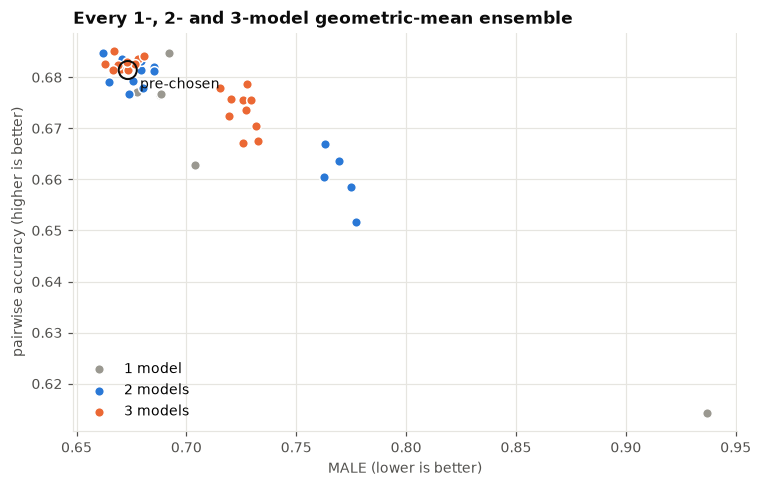

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, color in zip((1, 2, 3), (plots.GRAY, plots.BLUE, plots.ORANGE)):
    sub = ens[ens["size"] == k]
    ax.scatter(sub["male_mean"], sub["pa_mean"], s=40, color=color, edgecolors="white", linewidths=1, label=f"{k} model{'s' if k > 1 else ''}", zorder=3)
p = ens[ens.prechosen].iloc[0]
ax.scatter([p["male_mean"]], [p["pa_mean"]], s=140, facecolors="none", edgecolors=plots.INK, linewidths=1.3, zorder=4)
ax.annotate("pre-chosen", (p["male_mean"], p["pa_mean"]), textcoords="offset points", xytext=(8, -12), color=plots.INK)
ax.set(xlabel="MALE (lower is better)", ylabel="pairwise accuracy (higher is better)")
ax.legend(loc="lower left")
ax.set_title("Every 1-, 2- and 3-model geometric-mean ensemble", loc="left")
fig.tight_layout()
ens.sort_values("pa_mean", ascending=False).head(10)[["model", "mape_mean", "pa_mean", "rmse_mean", "male_mean"]].round(3)

## Takeaways

- The **pre-chosen ensemble** (RF + CatBoost + GP) is slightly better than its best member on MALE
  (0.673 vs 0.688) and pairwise accuracy (0.681 vs 0.677), with MAPE in between (1.44). The gains are
  about one std, so small but consistent with what ensembling usually gives.
- The best exploratory combinations reach PA ≈ 0.685 and MALE ≈ 0.66, but RF on the large feature set
  alone already gets PA 0.685, and choosing the best of 41 combinations on the same folds is optimistic.
- Combinations including fine-tuned CheMeleon are clearly worse (the cluster at the bottom right).
- Conclusion: ensembling is cheap and safe, but it doesn't change the picture. The ceiling comes from
  the data, not from the choice of model.